# JS09 - Lab Assignment 1: Distance Metrics x Data Size x Dimensions


In [ ]:
!pip install annoy faiss-cpu hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 9.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 49.7 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520035 sha256=f843b890f6bab9ca60940ba2cc7fe37892093fe0c8b8938ca92c4d27e425c151
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679796 sha256=a6154de0f626eb1a4bd8c373770344314ef4f0aa3ad48a072a06e88e0aeb17ce
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

In [ ]:
import numpy as np
import pandas as pd
import time
import faiss
import hnswlib
from annoy import AnnoyIndex

N_SMALL = 1_000
N_LARGE = 1_000_000
DIMS = [2, 5]
K = 10
N_QUERIES = 100
N_TREES = 10
SEARCH_K = 1000
M = 16
EF_CONSTRUCTION = 100
EF_SEARCH = 100
NPROBE = 10

METRICS = {
    'Euclidean': {'annoy': 'euclidean', 'hnsw': 'l2'},
    'Cosine': {'annoy': 'angular', 'hnsw': 'cosine'},
    'Inner Product': {'annoy': 'dot', 'hnsw': 'ip'},
}

## Helper functions

In [ ]:
def exact_knn(X, Q, metric, k):
    if metric == 'Euclidean':
        out = []
        for q in Q:
            d = ((X - q) ** 2).sum(axis=1)
            idx = np.argpartition(d, k)[:k]
            out.append(idx[np.argsort(d[idx])])
        return np.array(out)
    if metric == 'Cosine':
        Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
        Qn = Q / np.linalg.norm(Q, axis=1, keepdims=True)
        S = Qn @ Xn.T
    else:
        S = Q @ X.T
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(S, idx, axis=1), axis=1)
    return np.take_along_axis(idx, order, axis=1)

def recall(pred, truth, k):
    hits = sum(len(set(p[:k]) & set(t[:k])) for p, t in zip(pred, truth))
    return hits / (len(truth) * k)

def run_annoy(X, Q, metric):
    index = AnnoyIndex(X.shape[1], METRICS[metric]['annoy'])
    start = time.time()
    for i, v in enumerate(X):
        index.add_item(i, v)
    index.build(N_TREES)
    build = time.time() - start
    start = time.time()
    pred = [index.get_nns_by_vector(q, K, search_k=SEARCH_K) for q in Q]
    qtime = (time.time() - start) * 1000 / len(Q)
    return pred, build, qtime

def run_faiss(X, Q, metric):
    d = X.shape[1]
    Xf, Qf = X.copy(), Q.copy()
    if metric == 'Cosine':
        faiss.normalize_L2(Xf)
        faiss.normalize_L2(Qf)
    faiss_metric = faiss.METRIC_L2 if metric == 'Euclidean' else faiss.METRIC_INNER_PRODUCT
    nlist = max(4, min(100, len(X) // 40))
    quantizer = faiss.IndexFlatL2(d) if metric == 'Euclidean' else faiss.IndexFlatIP(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss_metric)
    start = time.time()
    train = Xf if len(Xf) <= 100_000 else Xf[np.random.choice(len(Xf), 100_000, replace=False)]
    index.train(train)
    index.add(Xf)
    build = time.time() - start
    index.nprobe = NPROBE
    start = time.time()
    pred = [index.search(q.reshape(1, -1), K)[1][0] for q in Qf]
    qtime = (time.time() - start) * 1000 / len(Q)
    return pred, build, qtime

def run_hnsw(X, Q, metric):
    index = hnswlib.Index(space=METRICS[metric]['hnsw'], dim=X.shape[1])
    start = time.time()
    index.init_index(max_elements=len(X), ef_construction=EF_CONSTRUCTION, M=M)
    index.add_items(X)
    build = time.time() - start
    index.set_ef(EF_SEARCH)
    start = time.time()
    pred = [index.knn_query(q.reshape(1, -1), k=K)[0][0] for q in Q]
    qtime = (time.time() - start) * 1000 / len(Q)
    return pred, build, qtime

RUNNERS = {'ANNOY': run_annoy, 'FAISS': run_faiss, 'HNSW': run_hnsw}

## Run all experiments

In [ ]:
rows = []
rng = np.random.default_rng(42)

for metric in METRICS:
    for n in (N_SMALL, N_LARGE):
        for dim in DIMS:
            X = rng.random((n, dim)).astype('float32')
            Q = rng.random((N_QUERIES, dim)).astype('float32')
            truth = exact_knn(X, Q, metric, K)
            for algo, runner in RUNNERS.items():
                pred, build, qtime = runner(X, Q, metric)
                rows.append({
                    'Metric': metric,
                    'Data/Dim': f'{n:,}/{dim}D',
                    'Algorithm': algo,
                    'Build (s)': build,
                    'Query (ms)': qtime,
                    'Recall@10': recall(pred, truth, K),
                })
                print(rows[-1])

results = pd.DataFrame(rows)
results.head()

{'Metric': 'Euclidean', 'Data/Dim': '1,000/2D', 'Algorithm': 'ANNOY', 'Build (s)': 0.04502511024475098, 'Query (ms)': 0.3621077537536621, 'Recall@10': 1.0}
{'Metric': 'Euclidean', 'Data/Dim': '1,000/2D', 'Algorithm': 'FAISS', 'Build (s)': 0.010522127151489258, 'Query (ms)': 0.06330013275146484, 'Recall@10': 1.0}
{'Metric': 'Euclidean', 'Data/Dim': '1,000/2D', 'Algorithm': 'HNSW', 'Build (s)': 0.07656383514404297, 'Query (ms)': 0.09378194808959961, 'Recall@10': 1.0}
{'Metric': 'Euclidean', 'Data/Dim': '1,000/5D', 'Algorithm': 'ANNOY', 'Build (s)': 0.03873419761657715, 'Query (ms)': 0.24013757705688477, 'Recall@10': 1.0}
{'Metric': 'Euclidean', 'Data/Dim': '1,000/5D', 'Algorithm': 'FAISS', 'Build (s)': 0.16687488555908203, 'Query (ms)': 0.06819486618041992, 'Recall@10': 0.999}
{'Metric': 'Euclidean', 'Data/Dim': '1,000/5D', 'Algorithm': 'HNSW', 'Build (s)': 0.09103727340698242, 'Query (ms)': 0.07584333419799805, 'Recall@10': 1.0}
{'Metric': 'Euclidean', 'Data/Dim': '1,000,000/2D', 'Algor

,Metric,Data/Dim,Algorithm,Build (s),Query (ms),Recall@10
0,Euclidean,"1,000/2D",ANNOY,0.045025,0.362108,1.000
1,Euclidean,"1,000/2D",FAISS,0.010522,0.063300,1.000
2,Euclidean,"1,000/2D",HNSW,0.076564,0.093782,1.000
3,Euclidean,"1,000/5D",ANNOY,0.038734,0.240138,1.000
4,Euclidean,"1,000/5D",FAISS,0.166875,0.068195,0.999


## Results Tables

In [ ]:
order = [f'{n:,}/{d}D' for n in (N_SMALL, N_LARGE) for d in DIMS]

def table(value):
    out = {}
    for metric in METRICS:
        sub = results[results['Metric'] == metric]
        pt = sub.pivot(index='Data/Dim', columns='Algorithm', values=value).loc[order]
        out[metric] = pt[['ANNOY', 'FAISS', 'HNSW']]
    return out

for title, value in [('Query time (ms/query)', 'Query (ms)'),
                     ('Recall@10', 'Recall@10'),
                     ('Build time (s)', 'Build (s)')]:
    print('=' * 10, title, '=' * 10)
    for metric, tb in table(value).items():
        print(f'\n{metric}')
        display(tb.round(4))

========== Query time (ms/query) ==========

Euclidean


Algorithm,ANNOY,FAISS,HNSW
Data/Dim,,,
"1,000/2D",0.3621,0.0633,0.0938
"1,000/5D",0.2401,0.0682,0.0758
"1,000,000/2D",0.2194,0.9263,0.0561
"1,000,000/5D",0.2453,0.9078,0.1084



Cosine


Algorithm,ANNOY,FAISS,HNSW
Data/Dim,,,
"1,000/2D",0.1158,0.0220,0.0246
"1,000/5D",0.1229,0.0293,0.0385
"1,000,000/2D",0.2133,1.0371,0.1031
"1,000,000/5D",0.3347,1.1126,0.0961



Inner Product


Algorithm,ANNOY,FAISS,HNSW
Data/Dim,,,
"1,000/2D",0.1574,0.0216,0.0280
"1,000/5D",0.1368,0.0222,0.0353
"1,000,000/2D",0.4118,2.0223,0.0370
"1,000,000/5D",0.2294,1.2365,0.0399


... (8 outputs left out)


Cosine


Algorithm,ANNOY,FAISS,HNSW
Data/Dim,,,
"1,000/2D",0.0435,0.0020,0.0258
"1,000/5D",0.0231,0.0022,0.0351
"1,000,000/2D",92.5457,0.4129,89.7921
"1,000,000/5D",29.5256,0.9005,85.4919



Inner Product


Algorithm,ANNOY,FAISS,HNSW
Data/Dim,,,
"1,000/2D",0.0538,0.0020,0.0307
"1,000/5D",0.0495,0.0021,0.0425
"1,000,000/2D",58.1978,1.2762,37.0277
"1,000,000/5D",49.9246,0.3755,66.7051


In [ ]:
summary = results.pivot_table(index=['Metric', 'Data/Dim'], columns='Algorithm',
                              values=['Query (ms)', 'Recall@10', 'Build (s)']).round(4)
summary

Build (s)                  Query (ms)          \
Algorithm                      ANNOY   FAISS     HNSW      ANNOY   FAISS   
Metric        Data/Dim                                                     
Cosine        1,000,000/2D   92.5457  0.4129  89.7921     0.2133  1.0371   
              1,000,000/5D   29.5256  0.9005  85.4919     0.3347  1.1126   
              1,000/2D        0.0435  0.0020   0.0258     0.1158  0.0220   
              1,000/5D        0.0231  0.0022   0.0351     0.1229  0.0293   
Euclidean     1,000,000/2D   32.8588  0.3103  54.8641     0.2194  0.9263   
              1,000,000/5D   20.9016  0.2424  93.9724     0.2453  0.9078   
              1,000/2D        0.0450  0.0105   0.0766     0.3621  0.0633   
              1,000/5D        0.0387  0.1669   0.0910     0.2401  0.0682   
Inner Product 1,000,000/2D   58.1978  1.2762  37.0277     0.4118  2.0223   
              1,000,000/5D   49.9246  0.3755  66.7051     0.2294  1.2365   
              1,000/2D        0.0538  0.0020   0.0307     0.1574  0.0216   
              1,000/5D        0.0495  0.0021   0.0425     0.1368  0.0222   

                                   Recall@10                
Algorithm                     HNSW     ANNOY  FAISS   HNSW  
Metric        Data/Dim                                      
Cosine        1,000,000/2D  0.1031     0.038  0.100  0.088  
              1,000,000/5D  0.0961     0.999  0.999  1.000  
              1,000/2D      0.0246     1.000  1.000  1.000  
              1,000/5D      0.0385     1.000  1.000  1.000  
Euclidean     1,000,000/2D  0.0561     1.000  1.000  1.000  
              1,000,000/5D  0.1084     1.000  1.000  1.000  
              1,000/2D      0.0938     1.000  1.000  1.000  
              1,000/5D      0.0758     1.000  0.999  1.000  
Inner Product 1,000,000/2D  0.0370     0.000  0.100  0.938  
              1,000,000/5D  0.0399     0.000  0.319  0.635  
              1,000/2D      0.0280     0.334  0.627  0.950  
              1,000/5D      0.0353     0.523  0.908  0.995

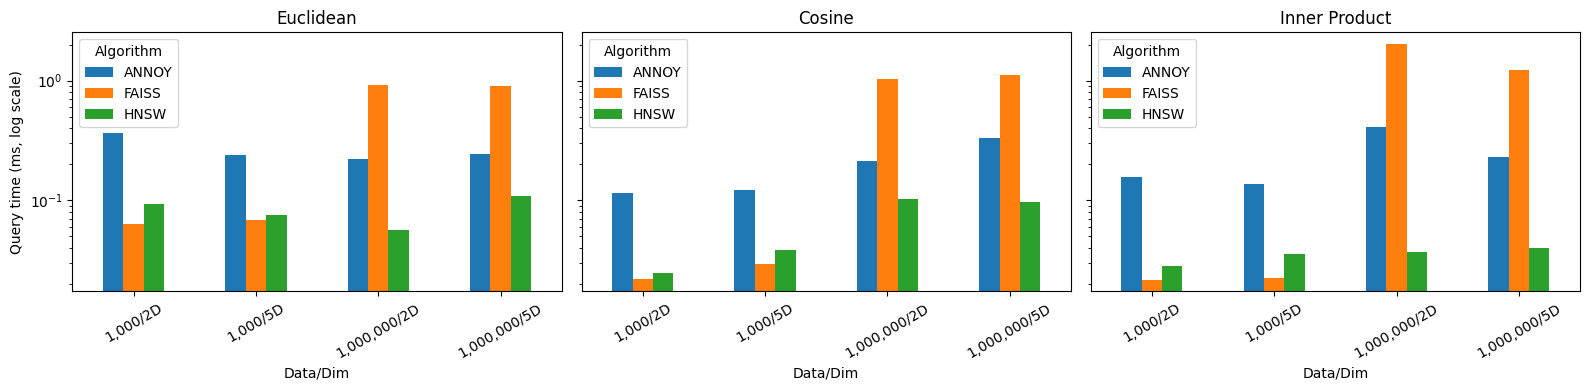

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(METRICS), figsize=(16, 4), sharey=True)
for ax, metric in zip(axes, METRICS):
    tb = table('Query (ms)')[metric]
    tb.plot(kind='bar', ax=ax, logy=True)
    ax.set_title(metric)
    ax.set_xlabel('Data/Dim')
    ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('Query time (ms, log scale)')
plt.tight_layout()
plt.show()

## Analysis

Read the tables above to answer:

- **Data size:** query time of the exact method grows with the number of points, while the ANN indexes stay close to constant. Build time grows with data size, and HNSW is usually the slowest to build.
- **Dimension:** going from 2D to 5D makes approximation harder, so recall can drop slightly for the same parameters.
- **Distance metric:** Euclidean and cosine behave similarly on random data; inner product on unnormalized vectors is much harder for ANNOY and FAISS IVF (their recall can drop sharply, because the nearest point by inner product is not the closest point in space), while HNSW usually stays high.
- **Trade-off:** compare recall against query time per algorithm to choose the best balance of accuracy and speed.